# NLP final Project By ==> Mahmoud Bassiouni <==

#                                        وَمَا تَوْفِيقِي إِلاَّ بِاللَّهِ عَلَيْهِ تَوَكَّلْتُ وَإِلَيْهِ أُنِيبُ   

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import os ,random,re,string,nltk,cv2

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from pathlib import Path

In [ ]:
# link_dataset="/kaggle/input/spam-email-dataset/emails.csv"

In [2]:
file_dir = '/kaggle/input/spam-email-dataset'
os.listdir(file_dir)

['emails.csv']

In [3]:
data = pd.read_csv(os.path.join(file_dir, 'emails.csv'))
data.head()

,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


In [4]:
data.tail()

,text,spam
5723,Subject: re : research and development charges...,0
5724,"Subject: re : receipts from visit jim , than...",0
5725,Subject: re : enron case study update wow ! a...,0
5726,"Subject: re : interest david , please , call...",0
5727,Subject: news : aurora 5 . 2 update aurora ve...,0


In [5]:
data['text'][5725]

'Subject: re : enron case study update  wow ! all on the same day . that \' s super . thank you so very much . vince  is coming up to baylor on monday of next week and we will hash out our  question list then .  thanks  john  at 04 : 54 pm 11 / 6 / 00 - 0600 , you wrote :  > good afternoon john ,  >  > i just want to drop you a line to update you re : andy fastow . i have  > confirmed a one hour interview slot with mr . fastow in monday , december 4 th  > from  > 11 : 00 a . m . - noon . this is in addition to your schedule interviews with  > mr . lay and mr . skilling - outline below .  >  > if you have any questions , please do not hesitate to contact me at  > 713 - 853 - 5670 .  >  > regards ,  >  > cindy  >  >  > - - - - - forwarded by cindy derecskey / corp / enron on 11 / 06 / 2000 04 : 49 pm - - - - -  >  > cindy  > derecskey to : " john martin "  > cc : vince j  kaminski / hou / ect @ ect , christie patrick / hou / ect @ ect  > 10 / 31 / 2000 subject : re : enron case  study ( 

In [6]:
data['spam'][5725]

0

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5728 non-null   object
 1   spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB


In [8]:

data.isnull().sum()

text    0
spam    0
dtype: int64

In [9]:

data.duplicated().sum()

33

In [10]:

data.drop_duplicates(inplace=True)
data.duplicated().sum()

0

In [11]:
data.reset_index(inplace=True)
data

,index,text,spam
0,0,Subject: naturally irresistible your corporate...,1
1,1,Subject: the stock trading gunslinger fanny i...,1
2,2,Subject: unbelievable new homes made easy im ...,1
3,3,Subject: 4 color printing special request add...,1
4,4,"Subject: do not have money , get software cds ...",1
...,...,...,...
5690,5723,Subject: re : research and development charges...,0
5691,5724,"Subject: re : receipts from visit jim , than...",0
5692,5725,Subject: re : enron case study update wow ! a...,0
5693,5726,"Subject: re : interest david , please , call...",0


In [12]:
data = data.drop('index', axis=1)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5695 entries, 0 to 5694
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5695 non-null   object
 1   spam    5695 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.1+ KB


<Axes: xlabel='spam'>

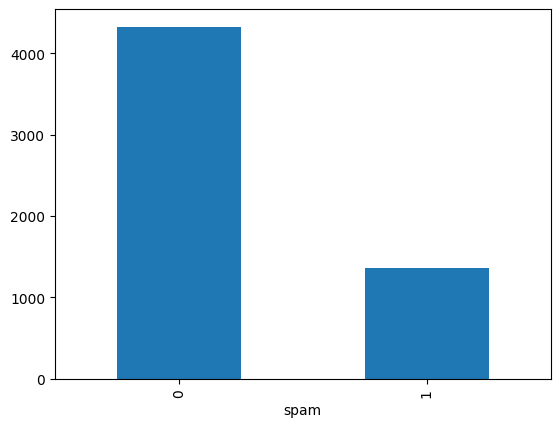

In [41]:
data['spam'].value_counts().plot.bar()

## Data Preprossing

In [13]:
data['text'] = data['text'].str.lower()
data['text'].head()

0    subject: naturally irresistible your corporate...
1    subject: the stock trading gunslinger  fanny i...
2    subject: unbelievable new homes made easy  im ...
3    subject: 4 color printing special  request add...
4    subject: do not have money , get software cds ...
Name: text, dtype: object

In [14]:
data['text'] = data['text'].str.replace(r'^subject\s*', '', case=False, regex=True)

In [15]:
translator = str.maketrans('', '', string.punctuation) 


data['text'] = data['text'].apply(lambda x: x.translate(translator))
data['text'].head()

0     naturally irresistible your corporate identit...
1     the stock trading gunslinger  fanny is merril...
2     unbelievable new homes made easy  im wanting ...
3     4 color printing special  request additional ...
4     do not have money  get software cds from here...
Name: text, dtype: object

In [16]:
data['text'] = data['text'].apply(word_tokenize)
data['text'].head()

0    [naturally, irresistible, your, corporate, ide...
1    [the, stock, trading, gunslinger, fanny, is, m...
2    [unbelievable, new, homes, made, easy, im, wan...
3    [4, color, printing, special, request, additio...
4    [do, not, have, money, get, software, cds, fro...
Name: text, dtype: object

In [17]:
stop_words = set(stopwords.words('english'))
def remove_stopwords (tokens):
    return [word for word in tokens if word not in stop_words]

data['text'] = data['text'].apply(remove_stopwords)
data['text'].head()

0    [naturally, irresistible, corporate, identity,...
1    [stock, trading, gunslinger, fanny, merrill, m...
2    [unbelievable, new, homes, made, easy, im, wan...
3    [4, color, printing, special, request, additio...
4    [money, get, software, cds, software, compatib...
Name: text, dtype: object

In [18]:
stemmer = PorterStemmer()
def stemming (tokens):
    tokens = [stemmer.stem(word) for word in tokens]
    return ' '.join(tokens)

stemmed_data = data.copy()
stemmed_data['text'] = stemmed_data['text'].apply(stemming)
stemmed_data['text'].head()

0    natur irresist corpor ident lt realli hard rec...
1    stock trade gunsling fanni merril muzo colza a...
2    unbeliev new home made easi im want show homeo...
3    4 color print special request addit inform cli...
4    money get softwar cd softwar compat great grow...
Name: text, dtype: object

In [19]:
lemmatizer = WordNetLemmatizer()
def lemmatizing(tokens):
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return ' '.join(tokens)

lemmatized_data = data.copy()
lemmatized_data['text'] = lemmatized_data['text'].apply(lemmatizing)
lemmatized_data['text'].head()

0    naturally irresistible corporate identity lt r...
1    stock trading gunslinger fanny merrill muzo co...
2    unbelievable new home made easy im wanting sho...
3    4 color printing special request additional in...
4    money get software cd software compatibility g...
Name: text, dtype: object

In [ ]:
def pos_tagging (tokens):
    pos_tags = nltk.pos_tag(tokens)
    return pos_tags

pos_tagged = data['text'].apply(pos_tagging)
pos_tagged.head()

## Feature Extraction

In [21]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split



# Bag-of-Words
bow_vectorizer = CountVectorizer()
bow_x = bow_vectorizer.fit_transform(lemmatized_data['text'])
bow_y = lemmatized_data['spam']

# Term Frequency-Inverse Document Frequency (TF-IDF)
tfidf_vectorizer = TfidfVectorizer()
tfidf_x = tfidf_vectorizer.fit_transform(lemmatized_data['text'])
tfidf_y = lemmatized_data['spam']

In [22]:
bow_y

0       1
1       1
2       1
3       1
4       1
       ..
5690    0
5691    0
5692    0
5693    0
5694    0
Name: spam, Length: 5695, dtype: int64

In [23]:
tfidf_y

0       1
1       1
2       1
3       1
4       1
       ..
5690    0
5691    0
5692    0
5693    0
5694    0
Name: spam, Length: 5695, dtype: int64

In [24]:
tfidf_x_train, tfidf_x_test, tfidf_y_train, tfidf_y_test = train_test_split(tfidf_x, tfidf_y, test_size=0.2, random_state=42)
bow_x_train, bow_x_test, bow_y_train, bow_y_test = train_test_split(bow_x, bow_y, test_size=0.2, random_state=42)

In [25]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report




nb_model = MultinomialNB() # Train Naive Bayes classifier
nb_model.fit(tfidf_x_train, tfidf_y_train)

MultinomialNB()

In [26]:
import pickle


with open("spam_model.pkl", "wb") as f:
    pickle.dump(nb_model, f)

with open("tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf_vectorizer, f)


In [27]:
nb_train_predictions = nb_model.predict(tfidf_x_train)
nb_test_predictions = nb_model.predict(tfidf_x_test)

train_accuracy = accuracy_score(tfidf_y_train, nb_train_predictions)# ==> y_train, y_prediction
print(f'Naive Bayes Training Accuracy: {train_accuracy:.5f}')

test_accuracy = accuracy_score(tfidf_y_test, nb_test_predictions)
print(f'Naive Bayes Test Accuracy: {test_accuracy:.5f}')

Naive Bayes Training Accuracy: 0.92647
Naive Bayes Test Accuracy: 0.88674


In [28]:
print(classification_report(tfidf_y_test, nb_test_predictions))

              precision    recall  f1-score   support

           0       0.87      1.00      0.93       843
           1       1.00      0.56      0.72       296

    accuracy                           0.89      1139
   macro avg       0.93      0.78      0.83      1139
weighted avg       0.90      0.89      0.87      1139



## LSTM Models

In [29]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

2025-09-23 06:58:35.814853: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1758610716.078724      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1758610716.163816      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [30]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(data['text'])
sequences = tokenizer.texts_to_sequences(data['text'])
X = pad_sequences(sequences, maxlen=100)
y = to_categorical(data['spam'])

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [32]:
lstm_model = Sequential()
lstm_model.add(Embedding(input_dim=len(tokenizer.word_index) + 1, output_dim=128, input_length=100))
lstm_model.add(LSTM(128))
lstm_model.add(Dense(2, activation='sigmoid'))


lstm_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])


lstm_model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.2)

Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
2025-09-23 06:58:51.483143: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


57/57 ━━━━━━━━━━━━━━━━━━━━ 15s 177ms/step - accuracy: 0.7965 - loss: 0.4805 - val_accuracy: 0.9660 - val_loss: 0.0878
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 164ms/step - accuracy: 0.9918 - loss: 0.0344 - val_accuracy: 0.9825 - val_loss: 0.0542
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 169ms/step - accuracy: 1.0000 - loss: 0.0043 - val_accuracy: 0.9825 - val_loss: 0.0698
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 171ms/step - accuracy: 1.0000 - loss: 0.0024 - val_accuracy: 0.9814 - val_loss: 0.0689
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 166ms/step - accuracy: 1.0000 - loss: 0.0032 - val_accuracy: 0.9857 - val_loss: 0.0688


## Evaluate the model

In [33]:
loss, accuracy = lstm_model.evaluate(X_test, y_test)
print("LSTM Accuracy:", accuracy)

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9830 - loss: 0.0765
LSTM Accuracy: 0.985952615737915


In [34]:
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score
import numpy as np

In [35]:
# Get predictions from Naive Bayes model
nb_predictions = nb_model.predict(tfidf_x_test)


accuracy_nb = accuracy_score(tfidf_y_test, nb_test_predictions)
precision_nb = precision_score(tfidf_y_test, nb_test_predictions)
recall_nb = recall_score(tfidf_y_test, nb_test_predictions)
f1_nb = f1_score(tfidf_y_test, nb_test_predictions)


print("Naive Bayes Classification Report:")
print(classification_report(tfidf_y_test, nb_test_predictions))


print(f"Naive Bayes - Accuracy: {accuracy_nb:.4f}, Precision: {precision_nb:.4f}, Recall: {recall_nb:.4f}, F1-score: {f1_nb:.4f}")

Naive Bayes Classification Report:
              precision    recall  f1-score   support

           0       0.87      1.00      0.93       843
           1       1.00      0.56      0.72       296

    accuracy                           0.89      1139
   macro avg       0.93      0.78      0.83      1139
weighted avg       0.90      0.89      0.87      1139

Naive Bayes - Accuracy: 0.8867, Precision: 1.0000, Recall: 0.5642, F1-score: 0.7214


In [36]:
# Get predictions from LSTM model
lstm_predictions = lstm_model.predict(X_test)
lstm_predicted_labels = np.argmax(lstm_predictions, axis=1)

# If y_test is one-hot encoded, convert it back to binary labels
if len(y_test.shape) > 1 and y_test.shape[1] > 1:
    y_test = np.argmax(y_test, axis=1)


accuracy_lstm = accuracy_score(y_test, lstm_predicted_labels)
precision_lstm = precision_score(y_test, lstm_predicted_labels)
recall_lstm = recall_score(y_test, lstm_predicted_labels)
f1_lstm = f1_score(y_test, lstm_predicted_labels)


print("LSTM Classification Report:")
print(classification_report(y_test, lstm_predicted_labels))


print(f"LSTM - Accuracy: {accuracy_lstm:.4f}, Precision: {precision_lstm:.4f}, Recall: {recall_lstm:.4f}, F1-score: {f1_lstm:.4f}")

36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step
LSTM Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       843
           1       0.99      0.96      0.97       296

    accuracy                           0.99      1139
   macro avg       0.99      0.98      0.98      1139
weighted avg       0.99      0.99      0.99      1139

LSTM - Accuracy: 0.9860, Precision: 0.9895, Recall: 0.9561, F1-score: 0.9725


In [37]:
print("=== Model Comparison ===")
print(f"Naive Bayes - Accuracy: {accuracy_nb:.4f}, Precision: {precision_nb:.4f}, Recall: {recall_nb:.4f}, F1-score: {f1_nb:.4f}")
print(f"LSTM        - Accuracy: {accuracy_lstm:.4f}, Precision: {precision_lstm:.4f}, Recall: {recall_lstm:.4f}, F1-score: {f1_lstm:.4f}")

=== Model Comparison ===
Naive Bayes - Accuracy: 0.8867, Precision: 1.0000, Recall: 0.5642, F1-score: 0.7214
LSTM        - Accuracy: 0.9860, Precision: 0.9895, Recall: 0.9561, F1-score: 0.9725


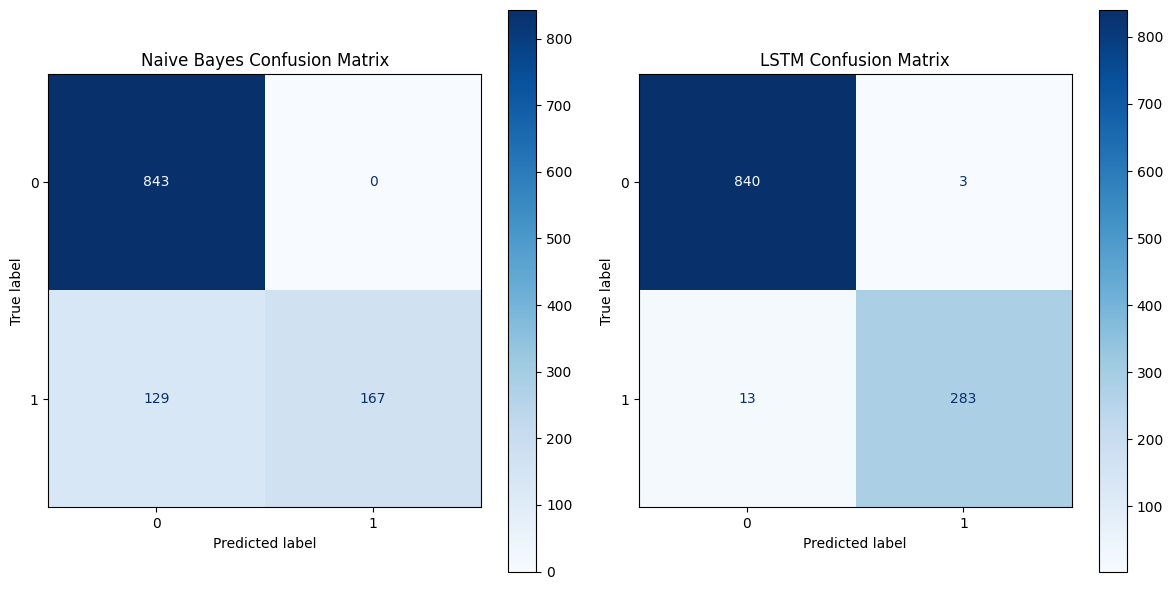

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create subplots: 1 row, 2 columns
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

# Naive Bayes Confusion Matrix
nb_conf_matrix = confusion_matrix(tfidf_y_test, nb_test_predictions)
disp_nb = ConfusionMatrixDisplay(confusion_matrix=nb_conf_matrix)
disp_nb.plot(cmap=plt.cm.Blues, ax=ax1)  # Plot in first subplot (ax1)
ax1.set_title("Naive Bayes Confusion Matrix")

# LSTM Confusion Matrix
lstm_conf_matrix = confusion_matrix(y_test, lstm_predicted_labels)
disp_lstm = ConfusionMatrixDisplay(confusion_matrix=lstm_conf_matrix)
disp_lstm.plot(cmap=plt.cm.Blues, ax=ax2)  # Plot in second subplot (ax2)
ax2.set_title("LSTM Confusion Matrix")

# Adjust layout and display
plt.tight_layout()
plt.show()